In [11]:
pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-macosx_10_15_universal2.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.0-cp314-cp314-macosx_10_15_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl (5.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# Lab: Train the Robot Vacuum

In the lecture, a robot vacuum learned its way back to its charging dock using Q-learning. Today you will build that robot and watch it learn.

```
+--------+--------+--------+--------+
|   A    |   B    |   C    |  DOCK  |   DOCK: +10, the run ends
+--------+--------+--------+--------+
|   D    |  SOFA  |   E    | STAIRS |   STAIRS: -10, the run ends
+--------+--------+--------+--------+
|   F    |   G    |   H    |   I    |   any other move: -1
+--------+--------+--------+--------+   walls and the sofa: the robot stays put, still -1
  start
```

The robot starts on F. It doesn't know where the dock or the stairs are: everything it learns comes from the rewards it gets.

## What you'll do

**1. Write Q-learning.** The first code cell contains everything the robot needs. Most of it is already written. Four small pieces are left for you:

| Task | Function | What it does |
|---|---|---|
| 1 | `new_q_table()` | Create an empty Q-table: 9 squares × 4 moves, all 0 |
| 2 | `update()` | Work out the target, and nudge the old Q-value towards it |
| 3 | `best_move()`, `choose_move()` | Epsilon-greedy: usually take the best move, sometimes a random one |
| 4 | `run_episode()` | The learning loop: one run from F to the dock or the stairs |

**2. Experiment.** The second code cell trains your robot and draws two figures. Change a setting, run it again, and see what happens.

## How to work

- Run the first code cell now. At the bottom, it checks each task and prints PASS, NOT YET or NOT QUITE (with a hint). Everything starts as NOT YET.
- Do the tasks in order, and run the cell again after each one.
- Each function has hints in its description, between the triple quotes. Read them carefully: they take you most of the way.

In [12]:
# =============================================================================
# Lab: Train the Robot Vacuum (Q-learning)
# Run this cell after every change you make. The checks at the very bottom
# tell you how each task is going: PASS, NOT YET, or NOT QUITE (with a hint).
# =============================================================================


import random
import copy

# -----------------------------------------------------------------------------
# PART 1. The room. Written for you: read it, but don't change it.
# -----------------------------------------------------------------------------
#
#   +--------+--------+--------+--------+
#   |   A    |   B    |   C    |  DOCK  |   DOCK   = charging dock: +10, the run ends
#   +--------+--------+--------+--------+
#   |   D    |  SOFA  |   E    | STAIRS |   STAIRS = falls down: -10, the run ends
#   +--------+--------+--------+--------+
#   |   F    |   G    |   H    |   I    |   any other move: -1 (battery)
#   +--------+--------+--------+--------+   walls and the sofa: the robot stays put, still -1
#     start

LAYOUT = ["ABC+",   # top row:    A  B  C  DOCK
          "D#E-",   # middle row: D  SOFA  E  STAIRS
          "FGHI"]   # bottom row: F  G  H  I
DOCK, STAIRS, SOFA = "+", "-", "#"
LABEL = {DOCK: "DOCK", STAIRS: "STAIRS", SOFA: "SOFA"}

MOVES = ["up", "right", "down", "left"]
STEP = {"up": (-1, 0), "right": (0, 1), "down": (1, 0), "left": (0, -1)}
SIDEWAYS = {"up": ("left", "right"), "down": ("left", "right"),
            "left": ("up", "down"), "right": ("up", "down")}   # where a slip takes the robot

POSITION = {cell: (r, c) for r, row in enumerate(LAYOUT) for c, cell in enumerate(row)}
SQUARES = [cell for row in LAYOUT for cell in row if cell.isalpha()]   # the 9 squares A to I


def is_end(square):
    """True at the dock or at the bottom of the stairs: the run is over."""
    return square in (DOCK, STAIRS)


class Room:
    """The robot's world. The robot makes a move, and the room tells it
    where it ended up and what reward it got. That is all the robot sees."""

    def __init__(self, move_cost=-1, dock_reward=10, stairs_reward=-10, slip=0.0, rng=None):
        self.move_cost = move_cost
        self.dock_reward = dock_reward
        self.stairs_reward = stairs_reward
        self.slip = slip                    # chance of slipping sideways on a wet floor
        self.rng = rng or random.Random()

    def result(self, square, move):
        """The rules of the room: where a move leads and what it scores."""
        r, c = POSITION[square]
        dr, dc = STEP[move]
        nr, nc = r + dr, c + dc
        off_the_grid = not (0 <= nr < len(LAYOUT) and 0 <= nc < len(LAYOUT[0]))
        if off_the_grid or LAYOUT[nr][nc] == SOFA:
            return square, self.move_cost          # bump: stay put, still pay for the move
        new_square = LAYOUT[nr][nc]
        if new_square == DOCK:
            return new_square, self.dock_reward
        if new_square == STAIRS:
            return new_square, self.stairs_reward
        return new_square, self.move_cost

    def outcomes(self, move):
        """What can happen when the robot tries a move: a list of (chance, actual move)."""
        if self.slip == 0:
            return [(1.0, move)]
        side1, side2 = SIDEWAYS[move]
        return [(1 - self.slip, move), (self.slip / 2, side1), (self.slip / 2, side2)]

    def take_move(self, square, move):
        """Make a move in the room. Returns (new_square, reward).
        On a wet floor the robot sometimes slips sideways instead."""
        if self.slip > 0 and self.rng.random() < self.slip:
            move = self.rng.choice(SIDEWAYS[move])
        return self.result(square, move)


# -----------------------------------------------------------------------------
# PART 2. YOUR CODE: Tasks 1 to 4.
# Do them in order. In each function, delete the "raise NotImplementedError"
# line and write your code in its place. Then run this cell again.
# -----------------------------------------------------------------------------


def new_q_table() -> dict[str, dict[str,float]]:
    """ simpler mate: just return a dict of dicts where key = square id, value = score for landing on that square"""
    return {square: {move : 0.0 for move in MOVES} for square in SQUARES}
    


def update(
    Q: dict[str, dict[str, float]],
    s: str,
    a: str,
    r: float,
    s2: str,
    alpha: float,
    gamma: float,
) -> float:
    """ update the square value based on the move that occurs"""
    if is_end(s2):
        target = r
    else:
        target = r + gamma * max(Q[s2].values())
        
    Q[s][a] = Q[s][a] + alpha * (target - Q[s][a])
    return target


def best_move(Q : dict[str, dict[str, float]], square : str, rng : float):
    best_value = max(Q[square].values())
    best_choices = [move for move, value in Q[square].items() if abs(value - best_value) < 1e-9]
    return rng.choice(best_choices)


def any_move(rng):
    """A random move: what the robot does when it explores. (Written for you.)"""
    return rng.choice(MOVES)


def choose_move(Q, square, epsilon, rng):
    if rng.random() < epsilon:
        return any_move(rng)
    return best_move(Q, square, rng)


def run_episode(Q, room, alpha, gamma, epsilon, rng, start="F", max_moves=200):
    s = start
    total = 0
    for _ in range(max_moves):
        if is_end(s):
            break
        
        a = choose_move(Q, s, epsilon, rng)
        s2, r = room.take_move(s, a) 
        update(Q, s, a, r, s2, alpha, gamma)
        total += r
        s = s2
        
    return total


# -----------------------------------------------------------------------------
# PART 3. Helpers. Written for you: training, printing and drawing.
# -----------------------------------------------------------------------------

def train(room, alpha, gamma, epsilon, episodes, rng):
    """Start with an empty Q-table and run many episodes.
    Returns the Q-table and the total reward of each episode."""
    Q = new_q_table()
    totals = []
    for _ in range(episodes):
        totals.append(run_episode(Q, room, alpha, gamma, epsilon, rng))
    return Q, totals


def plan(room, gamma, sweeps=1000):
    """The exact Q-values, worked out from the room's rules. The robot can't do
    this, because it doesn't know the rules. We only use it to check your code."""
    Q = {square: {move: 0.0 for move in MOVES} for square in SQUARES}
    for _ in range(sweeps):
        for s in SQUARES:
            for a in MOVES:
                value = 0.0
                for chance, actual_move in room.outcomes(a):
                    s2, r = room.result(s, actual_move)
                    future = 0.0 if is_end(s2) else gamma * max(Q[s2].values())
                    value += chance * (r + future)
                Q[s][a] = value
    return Q


def fmt(value):
    """Whole numbers without decimals, others with one decimal place."""
    if abs(value) < 0.05:
        return "0"
    if abs(value - round(value)) < 0.05:
        return f"{round(value)}"
    return f"{value:.1f}"


def follow_policy(Q, room, start="F", max_moves=30):
    """Follow the best moves from the start on a dry floor. Returns (route as text, total)."""
    s, total, route, seen = start, 0, [start], {start}
    for _ in range(max_moves):
        best = max(Q[s].values())
        a = next(m for m in MOVES if Q[s][m] == best)
        s, r = room.result(s, a)
        total += r
        route += [a, LABEL.get(s, s)]
        if is_end(s):
            return " ".join(route), fmt(total)
        if s in seen:
            return " ".join(route) + " ... and round again", "never ends"
        seen.add(s)
    return " ".join(route) + " ...", "never ends"


ARROW_STEP = {"up": (0, 1), "right": (1, 0), "down": (0, -1), "left": (-1, 0)}


def draw_room(Q, ax, title=""):
    """Draw the room: each square's four Q-values, and arrows for its best moves."""
    import matplotlib.patches as patches
    colours = {DOCK: "#DCE7F8", STAIRS: "#F7DCC9", SOFA: "#DEDBD3"}
    for r, row in enumerate(LAYOUT):
        for c, cell in enumerate(row):
            x, y = c, len(LAYOUT) - 1 - r
            ax.add_patch(patches.Rectangle((x + 0.03, y + 0.03), 0.94, 0.94, linewidth=1.5,
                                           edgecolor="#9DB7E6" if cell in Q else "#CFCBC1",
                                           facecolor=colours.get(cell, "#FDFCF9")))
            cx, cy = x + 0.5, y + 0.5
            if cell not in Q:
                text = {DOCK: "DOCK\n+10", STAIRS: "STAIRS\n-10", SOFA: "SOFA"}[cell]
                ax.text(cx, cy, text, ha="center", va="center", fontsize=11, fontweight="bold",
                        color={DOCK: "#2452A8", STAIRS: "#8F3F10", SOFA: "#4A5263"}[cell])
                continue
            best = max(Q[cell].values())
            ax.text(x + 0.1, y + 0.86, cell, ha="left", va="center", fontsize=11,
                    fontweight="bold", color="#17233B")
            for move, (dx, dy) in ARROW_STEP.items():
                value = Q[cell][move]
                is_best = abs(value - best) < 0.05
                ax.text(cx + dx * 0.36, cy + dy * 0.36, fmt(value), ha="center", va="center",
                        fontsize=9, color="#2452A8" if is_best else "#5F6673",
                        fontweight="bold" if is_best else "normal")
                if is_best:
                    ax.annotate("", xy=(cx + dx * 0.22, cy + dy * 0.22), xytext=(cx, cy),
                                arrowprops=dict(arrowstyle="-|>", color="#2F64C8", lw=2))
            if cell == "F":
                ax.add_patch(patches.Circle((x + 0.14, y + 0.14), 0.07, color="#17233B"))
    ax.set_xlim(0, len(LAYOUT[0]))
    ax.set_ylim(0, len(LAYOUT))
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)


# -----------------------------------------------------------------------------
# PART 4. The checks. Written for you: they run every time you run this cell.
# -----------------------------------------------------------------------------

def check_task1():
    Q = new_q_table()
    assert isinstance(Q, dict), "new_q_table() should return a dictionary"
    assert set(Q) == set(SQUARES), "there should be one entry for each square, A to I (not the dock, stairs or sofa)"
    for s in SQUARES:
        assert isinstance(Q[s], dict) and set(Q[s]) == set(MOVES), f"Q['{s}'] should be a dictionary with one entry for each of {MOVES}"
        assert all(v == 0 for v in Q[s].values()), "every Q-value should start at 0"


def check_task2():
    Q = new_q_table()
    out = update(Q, "F", "up", -1, "D", 1.0, 1.0)
    assert Q["F"]["up"] == -1, f"the very first update: Q(F, up) = -1 + 0 = -1, yours is {Q['F']['up']}"
    assert out == -1, "update() should return the target (here -1)"
    Q["C"]["right"] = 10
    update(Q, "B", "right", -1, "C", 1.0, 1.0)
    assert Q["B"]["right"] == 9, f"Q(B, right) = -1 + 10 = 9, yours is {Q['B']['right']}"
    Q["C"]["right"] = 0
    try:
        update(Q, "C", "right", 10, DOCK, 1.0, 1.0)
    except KeyError:
        raise AssertionError("the dock and the stairs have no Q-values: when is_end(s2), the target is just r")
    assert Q["C"]["right"] == 10, "a move that ends the run: the target is just r"
    Q = new_q_table()
    Q["A"]["right"], Q["B"]["right"] = 4, 9
    update(Q, "A", "right", -1, "B", 0.5, 1.0)
    assert Q["A"]["right"] == 6, f"with alpha 0.5, an old value of 4 and a target of 8, the new value is 6 (halfway); yours is {Q['A']['right']}"
    Q = new_q_table()
    Q["C"]["right"] = 10
    update(Q, "B", "right", -1, "C", 1.0, 0.9)
    assert abs(Q["B"]["right"] - 8) < 1e-9, f"with gamma 0.9: -1 + 0.9 x 10 = 8, yours is {Q['B']['right']}"


def check_task3():
    rng = random.Random(0)
    Q = new_q_table()
    Q["F"]["up"], Q["F"]["right"] = 6, 2
    assert best_move(Q, "F", rng) == "up", "best_move should return the move with the highest Q-value"
    Q["F"]["right"] = 6
    picks = {best_move(Q, "F", rng) for _ in range(200)}
    assert picks == {"up", "right"}, f"up and right tie at 6, so both should be picked sometimes; you picked {picks}"
    Q["F"]["right"] = 2
    assert all(choose_move(Q, "F", 0.0, rng) == "up" for _ in range(200)), "with epsilon 0 the robot should always exploit"
    moves = [choose_move(Q, "F", 1.0, rng) for _ in range(4000)]
    for m in MOVES:
        assert 800 < moves.count(m) < 1200, "with epsilon 1 every move should be picked about equally often"
    ups = sum(choose_move(Q, "F", 0.1, rng) == "up" for _ in range(4000)) / 4000
    assert 0.89 < ups < 0.96, f"with epsilon 0.1 the best move should be picked about 92.5% of the time; yours {ups:.0%}"


def check_task4():
    room = Room()
    exact = plan(room, 1.0)
    total = run_episode(copy.deepcopy(exact), room, 1.0, 1.0, 0.0, random.Random(0), start="F")
    assert total == 6, f"following the best moves from F should score 6; yours scored {total}"
    total = run_episode(copy.deepcopy(exact), room, 1.0, 1.0, 0.0, random.Random(0), start="C")
    assert total == 10, f"from C the best run is one move onto the dock, worth 10; yours scored {total}"
    Q = new_q_table()
    run_episode(Q, room, 0.5, 1.0, 0.1, random.Random(0), start="F")
    assert any(v != 0 for row in Q.values() for v in row.values()), "after one run some Q-values should have changed: did you call update()?"


CHECKS = [("Task 1", "new_q_table()", check_task1),
          ("Task 2", "update()", check_task2),
          ("Task 3", "best_move(), choose_move()", check_task3),
          ("Task 4", "run_episode()", check_task4)]


def task_status(test):
    try:
        test()
        return "PASS"
    except NotImplementedError as e:
        return f"NOT YET ({e})"
    except AssertionError as e:
        return f"NOT QUITE: {e}"
    except Exception as e:
        return f"ERROR: {type(e).__name__}: {e}"


def tasks_done():
    return all(task_status(test) == "PASS" for _, _, test in CHECKS)


def trace_episodes():
    """The six episodes we worked through by hand in the lecture, now done by YOUR update()."""
    room, Q = Room(), new_q_table()
    best_route = ["up", "up", "right", "right", "right"]
    for number, moves in [(n, best_route) for n in range(1, 6)] + [(6, ["right", "right", "up", "right"])]:
        print(f"  Episode {number}: from F, " + ", ".join(moves))
        s = "F"
        for a in moves:
            s2, r = room.take_move(s, a)
            old = Q[s][a]
            target = update(Q, s, a, r, s2, 1.0, 1.0)
            changed = "   <- changed" if Q[s][a] != old else ""
            if is_end(s2):
                print(f"    Q({s}, {a}) = {fmt(Q[s][a])}  ({LABEL[s2].lower()}: run over){changed}")
            else:
                print(f"    Q({s}, {a}) = {fmt(r)} + {fmt(target - r)} = {fmt(Q[s][a])}{changed}")
            s = s2


results = [(name, what, task_status(test)) for name, what, test in CHECKS]
for name, what, status in results:
    print(f"{name:<8} {what:<28} {status}")
if results[0][2] == "PASS" and results[1][2] == "PASS":
    print("\nYour update() on the six episodes from the lecture (alpha = 1, gamma = 1):")
    trace_episodes()
if all(status == "PASS" for _, _, status in results):
    print("\nAll four tasks pass. Now run the experiments cell below.")

Task 1   new_q_table()                PASS
Task 2   update()                     PASS
Task 3   best_move(), choose_move()   PASS
Task 4   run_episode()                PASS

Your update() on the six episodes from the lecture (alpha = 1, gamma = 1):
  Episode 1: from F, up, up, right, right, right
    Q(F, up) = -1 + 0 = -1   <- changed
    Q(D, up) = -1 + 0 = -1   <- changed
    Q(A, right) = -1 + 0 = -1   <- changed
    Q(B, right) = -1 + 0 = -1   <- changed
    Q(C, right) = 10  (dock: run over)   <- changed
  Episode 2: from F, up, up, right, right, right
    Q(F, up) = -1 + 0 = -1
    Q(D, up) = -1 + 0 = -1
    Q(A, right) = -1 + 0 = -1
    Q(B, right) = -1 + 10 = 9   <- changed
    Q(C, right) = 10  (dock: run over)
  Episode 3: from F, up, up, right, right, right
    Q(F, up) = -1 + 0 = -1
    Q(D, up) = -1 + 0 = -1
    Q(A, right) = -1 + 9 = 8   <- changed
    Q(B, right) = -1 + 10 = 9
    Q(C, right) = 10  (dock: run over)
  Episode 4: from F, up, up, right, right, right
    Q(F

## Experiments

This cell trains your robot for 300 runs, each starting on F. It then draws:

- **Figure 1:** the total reward of each run, so you can watch the robot improve.
- **Figure 2:** the Q-values it learned, with an arrow for the best move on each square.

It also prints the route the robot takes from F when it follows its best moves. You don't need to write any code here. Change one setting at the top, run the cell again, and compare.

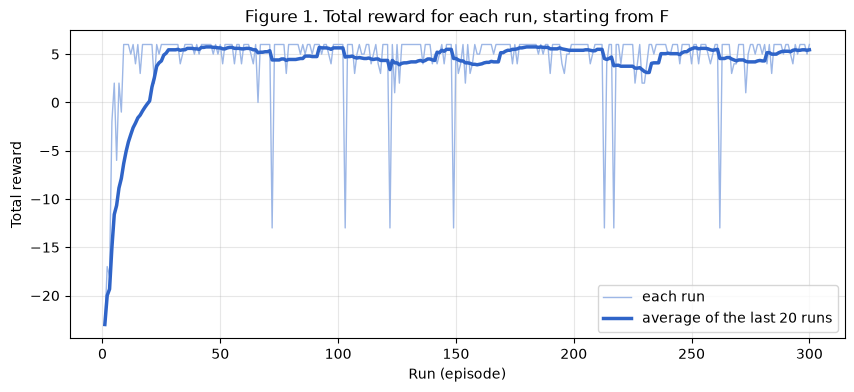

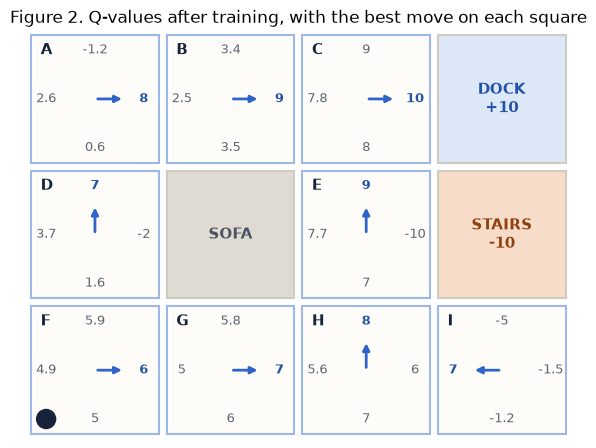

Average reward over the last 50 runs: 5.0
Following the best moves from F: F right G right H up E up C right DOCK  (total: 6)


In [13]:
# =============================================================================
# Experiments. Run this cell once Tasks 1 to 4 all say PASS.
# No code to write here: change a setting, run the cell again, and compare.
# =============================================================================
import matplotlib.pyplot as plt

# ---- SETTINGS ----------------------------------------------------------------
ALPHA = 0.5      # learning rate: how far each new target moves the old value
GAMMA = 1.0      # discount: how much a reward one move later still counts
EPSILON = 0.1    # how often the robot makes a random move
MOVE_COST = -1   # reward for an ordinary move
SLIP = 0.0       # chance of slipping sideways on a wet floor
# -------------------------------------------------------------------------------

EPISODES = 300

if not tasks_done():
    print("Finish Tasks 1 to 4 first: run the cell above until they all say PASS.")
else:
    rng = random.Random(1)
    room = Room(move_cost=MOVE_COST, slip=SLIP, rng=rng)
    Q, totals = train(room, ALPHA, GAMMA, EPSILON, EPISODES, rng)

    # Figure 1: how well each run went
    average = [sum(totals[max(0, i - 19):i + 1]) / len(totals[max(0, i - 19):i + 1])
               for i in range(EPISODES)]
    plt.figure(figsize=(10, 4))
    plt.plot(range(1, EPISODES + 1), totals, color="#9DB7E6", lw=1, label="each run")
    plt.plot(range(1, EPISODES + 1), average, color="#2F64C8", lw=2.5, label="average of the last 20 runs")
    plt.xlabel("Run (episode)")
    plt.ylabel("Total reward")
    plt.title("Figure 1. Total reward for each run, starting from F")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    # Figure 2: what the robot learned
    fig, ax = plt.subplots(figsize=(7, 5.5))
    draw_room(Q, ax, "Figure 2. Q-values after training, with the best move on each square")
    plt.show()

    route, total = follow_policy(Q, Room(move_cost=MOVE_COST), "F")
    print(f"Average reward over the last 50 runs: {sum(totals[-50:]) / 50:.1f}")
    print(f"Following the best moves from F: {route}  (total: {total})")

## Things to try

Discuss these in your team. Each one only needs a setting changed.

1. In Figure 2, follow the arrows from F. Do they lead to the dock? Some squares have numbers that look odd. Why might that be?
2. In Figure 1, why does the average settle around 5, when the best route scores 6?
3. Set `EPSILON = 0`, then `EPSILON = 0.3`. What changes, and why?
4. Set `MOVE_COST = 0`. Why do some squares now have several arrows? Then also set `GAMMA = 0.9`.
5. Set `MOVE_COST = 1`, so the robot earns a point for every move. What does it learn to do?
6. Set `SLIP = 0.2` to make the floor wet. Which way does the robot go from F now? Then also set `ALPHA = 1`. What happens to Figure 1?

1. The arrows do lead cleanly to the dock in the minimum amount of possible moves as well. Some numbers do look a little bizarre. Moving left on D (goes nowhere), and going up on C gives value 9 which is bizarre, but does sort of make sense as staying on those squares (you cant move in those directions so would stay there) is a better state than hitting a sofa.
2. The average settles around 5 instead of 6 because the robot's exploration rate epsilon causes it to occasionally take random moves—like bumping into walls or falling down the stairs—which drags down the average performance across the 50 runs.
3. With EPSILON = 0, the robot never explores and can get permanently stuck on a bad path, whereas EPSILON = 0.3 forces frequent random moves that help discover better routes but continuously drag down its final average score once trained.
4. With MOVE_COST = 0, taking extra steps costs nothing, so short and long paths to the dock are valued equally, creating multi-way ties (multiple arrows); setting GAMMA = 0.9 discounts future rewards over distance, breaking the ties in favor of the shortest path.
5. The robot learns to wander around the room infinitely in circles to harvest +1 point on every move, completely ignoring the charging dock because avoiding the end state maximizes its total score.
6. On a wet floor (SLIP = 0.2), the robot avoids the risky path near the stairs (-10) and chooses safer, wider routes; setting ALPHA = 1 causes Figure 1 to bounce around erratically because the robot overreacts to single random slips instead of learning a stable average.